#### Task_01: Dataset Loading and Initial View

In [23]:
import pandas as pd 
import numpy as numpy
import matplotlib.pyplot as plt 
import seaborn as sns

In [24]:
# Loading Dataset 
df = pd.read_csv("titanic.csv")

# Displaying shape(total rows x total columns)
print("Shape of dataset is ", df.shape)

# Displaying first 7 rows of dataset
df.head(7)

Shape of dataset is  (418, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
5,897,0,3,"Svensson, Mr. Johan Cervin",male,14.0,0,0,7538,9.2250,NaN,S
6,898,1,3,"Connolly, Miss. Kate",female,30.0,0,0,330972,7.6292,NaN,Q


#### Task_02: Data Exploration

In [25]:
# Displaying descriptive statistics
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,0.363636,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.481622,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,0.000000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,1.000000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


In [26]:
# Displaying some general information about dataframe like columns datatypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    str    
 4   Sex          418 non-null    str    
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    str    
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     str    
 11  Embarked     418 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 39.3 KB


In [27]:
# Displaying numerical columns
numerical_cols = df.select_dtypes(include='number')
print(numerical_cols)

     PassengerId  Survived  Pclass   Age  SibSp  Parch      Fare
0            892         0       3  34.5      0      0    7.8292
1            893         1       3  47.0      1      0    7.0000
2            894         0       2  62.0      0      0    9.6875
3            895         0       3  27.0      0      0    8.6625
4            896         1       3  22.0      1      1   12.2875
..           ...       ...     ...   ...    ...    ...       ...
413         1305         0       3   NaN      0      0    8.0500
414         1306         1       1  39.0      0      0  108.9000
415         1307         0       3  38.5      0      0    7.2500
416         1308         0       3   NaN      0      0    8.0500
417         1309         0       3   NaN      1      1   22.3583

[418 rows x 7 columns]


In [28]:
# Converting some categorical columns to 'category' datatype
df[['Survived', 'Pclass', 'Sex', 'SibSp', 'Parch', 'Cabin', 'Embarked']] = df[['Survived', 'Pclass', 'Sex',
                                                                                'SibSp', 'Parch', 'Cabin', 'Embarked']].astype('category')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  418 non-null    int64   
 1   Survived     418 non-null    category
 2   Pclass       418 non-null    category
 3   Name         418 non-null    str     
 4   Sex          418 non-null    category
 5   Age          332 non-null    float64 
 6   SibSp        418 non-null    category
 7   Parch        418 non-null    category
 8   Ticket       418 non-null    str     
 9   Fare         417 non-null    float64 
 10  Cabin        91 non-null     category
 11  Embarked     418 non-null    category
dtypes: category(7), float64(2), int64(1), str(2)
memory usage: 20.1 KB


In [29]:
# Displaying unique values and their frequency distributions to analyze categorical columns
print(df['Survived'].value_counts())
print("\n",df['Sex'].value_counts())
print("\n", df['Embarked'].value_counts())
print("\n", df['Pclass'].value_counts())

Survived
0    266
1    152
Name: count, dtype: int64

 Sex
male      266
female    152
Name: count, dtype: int64

 Embarked
S    270
C    102
Q     46
Name: count, dtype: int64

 Pclass
3    218
1    107
2     93
Name: count, dtype: int64


#### Task_03: Data Cleaning

In [30]:
# Checking for missing values
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [31]:
# Filling 'Age' and 'Fare' columns using median and dropping 'Cabin' column as it contains 78.23% null values.
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Fare'] = df['Fare'].fillna(df['Fare'].mean())
df = df.drop(['Cabin'], axis=1)

# Verifying that all missing values have been handled, successfully
df.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

#### Task_04: Feature Selection and renaming

In [32]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [33]:
cols = ['Sex', 'Embarked']
df1 = pd.get_dummies(df, columns=cols, drop_first=True)


In [34]:
df1.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Sex_male,Embarked_Q,Embarked_S
0,892,0,3,"Kelly, Mr. James",34.5,0,0,330911,7.8292,True,True,False
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",47.0,1,0,363272,7.0000,False,False,True
2,894,0,2,"Myles, Mr. Thomas Francis",62.0,0,0,240276,9.6875,True,True,False
3,895,0,3,"Wirz, Mr. Albert",27.0,0,0,315154,8.6625,True,False,True
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",22.0,1,1,3101298,12.2875,False,False,True


In [35]:
# Removing name column 
df1 = df1.drop(columns=['Name', 'Ticket'])

In [36]:
# Removing target variable 
X = df1.drop(['Survived'], axis=1)
Y = df1['Survived']

# Dividing dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.25, random_state=42)

# Building and training SVC model
svm = SVC(kernel='linear')
svm.fit(X_train, y_train)
y_pred = svm.predict(X_test)

# Model Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Model accuracy is ", accuracy)

Model accuracy is  1.0


In [37]:
# Confusion matrix
from sklearn.metrics import confusion_matrix
confusionMatrix = confusion_matrix(y_test, y_pred)
print("Confusion matrix for model: ", confusionMatrix)

# Precision
from sklearn.metrics import precision_score
precisionScore = precision_score(y_test, y_pred)
print("Precision score of model: ", precisionScore)

# Recall
from sklearn.metrics import recall_score
recallScore = recall_score(y_test, y_pred)
print("Recall score for model: ", recallScore)

# F1-score
from sklearn.metrics import f1_score
f1Score = f1_score(y_test, y_pred)
print("F1_Score of model: ", f1Score)

Confusion matrix for model:  [[69  0]
 [ 0 36]]
Precision score of model:  1.0
Recall score for model:  1.0
F1_Score of model:  1.0


#### Task_05: Data Visualization

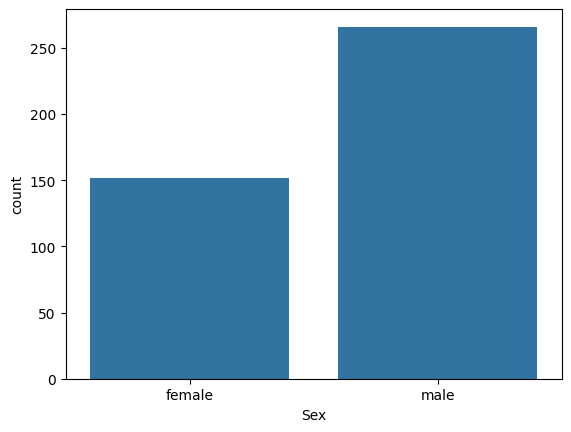

In [50]:
sns.countplot(data=df, x='Sex')
plt.show()

<Axes: xlabel='Fare', ylabel='Count'>

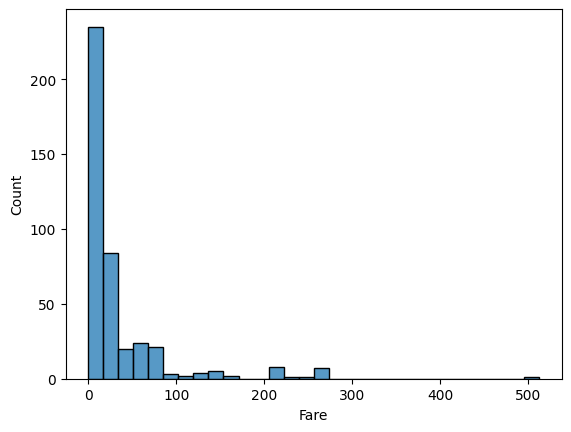

In [ ]:
sns.histplot(df['Fare'], bins=30)          # Right skewed

The Histplot of 'Fare' column is right skewed